# 02. Exploratory Data Analysis

Goal: get a descriptive picture of the cleaned data and decide which questions are worth a full analysis notebook.
This notebook **describes** the data. It does not test hypotheses or draw conclusions; that is the job of the notebooks that follow.

**Reading the data correctly**
- Every row is one goal, so only matches where Messi scored appear. Per-match or per-game rates cannot be computed from this file.
- The data covers club goals only (Barcelona, PSG, Inter Miami). Goals for the reserve team FC Barcelona B were removed in the cleaning step. There are no national team goals.
- The last season (2025-26) is partial; the data ends on 2026-03-07.

**Sections**
1. Overview
2. Goals over time
3. What the goals look like
4. Match context
5. Assists
6. Observations and candidate questions

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in notebooks/, so the repository root is one level up.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_PATH = REPO_ROOT / "data" / "clean" / "messi_goals_clean.csv"
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Minute buckets in time order, so charts do not sort them alphabetically.
MINUTE_BUCKET_ORDER = ["0-15", "16-30", "31-45", "46-60", "61-75", "76-90", "91+"]

goals = pd.read_csv(CLEAN_PATH, parse_dates=["date"])
goals["goal_minute_bucket"] = pd.Categorical(
    goals["goal_minute_bucket"], categories=MINUTE_BUCKET_ORDER, ordered=True
)

print(f"Rows: {len(goals)}, columns: {goals.shape[1]}")

Rows: 784, columns: 31


In [2]:
# ---- Chart style ---------------------------------------------------------
# One categorical palette, used in this fixed order. It was checked for
# color-blind separation, and the stacked charts also print a table and label
# the segments, because some of these colors are light on a white background.
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID_COLOR = "#e3e2de"

BLUE = "#2a78d6"      # used for every single-series chart
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
# Text color that stays readable on top of each categorical fill.
LABEL_ON_FILL = ["#ffffff", "#0b0b0b", "#0b0b0b", "#0b0b0b", "#0b0b0b", "#ffffff"]

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "text.color": TEXT_PRIMARY,
        "axes.labelcolor": TEXT_SECONDARY,
        "xtick.color": TEXT_SECONDARY,
        "ytick.color": TEXT_SECONDARY,
        "axes.edgecolor": GRID_COLOR,
    }
)


def style_axes(axes, grid_axis="y"):
    # Remove the top and right frame, keep a light grid on the value axis only.
    for side in ["top", "right"]:
        axes.spines[side].set_visible(False)
    axes.spines["left"].set_color(GRID_COLOR)
    axes.spines["bottom"].set_color(GRID_COLOR)
    axes.grid(axis=grid_axis, color=GRID_COLOR, linewidth=0.8)
    axes.set_axisbelow(True)
    axes.tick_params(length=0)


def add_title(axes, title, subtitle=None):
    # Left-aligned title with an optional smaller line under it.
    axes.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=24 if subtitle else 10)
    if subtitle:
        axes.text(0, 1.03, subtitle, transform=axes.transAxes, fontsize=9, color=TEXT_SECONDARY)


def save_figure(figure, file_name):
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name, dpi=150)
    plt.show()


def label_bars_vertical(axes, bars, number_format="{:.0f}"):
    # Write each bar's value just above it.
    for bar in bars:
        axes.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            number_format.format(bar.get_height()),
            ha="center", va="bottom", fontsize=9, color=TEXT_PRIMARY,
        )


def label_bars_horizontal(axes, bars, number_format="{:.0f}"):
    for bar in bars:
        axes.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            "  " + number_format.format(bar.get_width()),
            ha="left", va="center", fontsize=9, color=TEXT_PRIMARY,
        )

## 1. Overview

In [3]:
matches = goals["match_id"].nunique()
summary = pd.Series(
    {
        "Goals (rows)": len(goals),
        "Matches with at least one goal": matches,
        "Goals per scoring match": round(len(goals) / matches, 2),
        "Seasons": goals["season"].nunique(),
        "First goal": goals["date"].min().date(),
        "Last goal": goals["date"].max().date(),
        "Competitions": goals["competition"].nunique(),
        "Opponents": goals["opponent"].nunique(),
        "Assisting players": goals["assist_player"].nunique(),
    },
    name="value",
)
summary.to_frame()

,value
Goals (rows),784
Matches with at least one goal,512
Goals per scoring match,1.53
Seasons,22
First goal,2005-05-01
Last goal,2026-03-07
Competitions,12
Opponents,121
Assisting players,84


In [ ]:
goals_by_club = goals["club"].value_counts().rename("goals").to_frame()
goals_by_club["share"] = (goals_by_club["goals"] / len(goals)).round(3)
goals_by_club

,goals,share
club_group,,
FC Barcelona,672,0.857
Inter Miami CF,80,0.102
Paris Saint-Germain,32,0.041


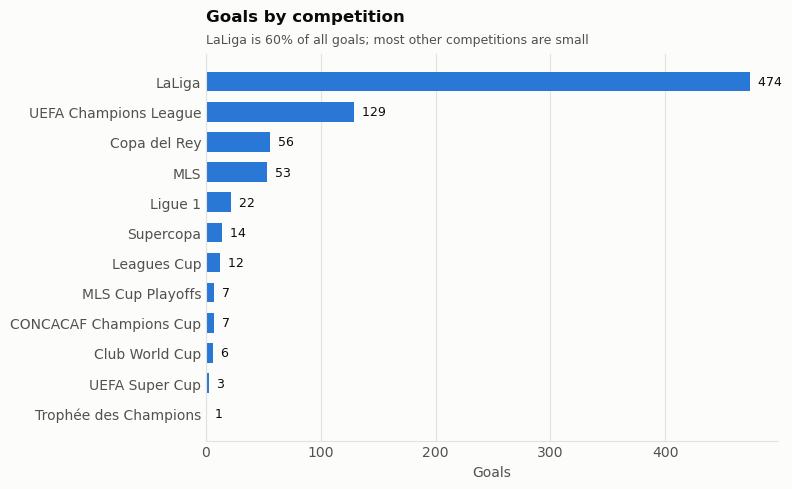

In [5]:
goals_by_competition = goals["competition"].value_counts().sort_values()

figure, axes = plt.subplots(figsize=(8, 5))
bars = axes.barh(goals_by_competition.index, goals_by_competition.values, color=BLUE, height=0.65)
label_bars_horizontal(axes, bars)
style_axes(axes, grid_axis="x")
axes.set_xlabel("Goals")
add_title(axes, "Goals by competition", "LaLiga is 60% of all goals; most other competitions are small")
save_figure(figure, "eda_goals_by_competition.png")

## 2. Goals over time

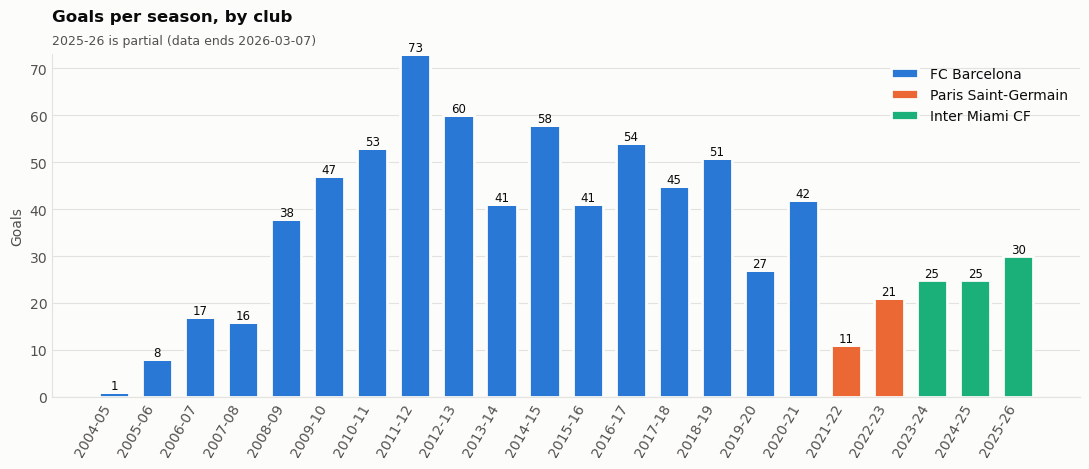

In [ ]:
goals_by_season_club = (
    goals.groupby(["season", "club"]).size().unstack(fill_value=0)
)
club_order = ["FC Barcelona", "Paris Saint-Germain", "Inter Miami CF"]
goals_by_season_club = goals_by_season_club[club_order]

figure, axes = plt.subplots(figsize=(11, 4.8))
bottoms = np.zeros(len(goals_by_season_club))
x_positions = np.arange(len(goals_by_season_club))

for color, club in zip(CATEGORICAL, club_order):
    values = goals_by_season_club[club].values
    axes.bar(
        x_positions, values, bottom=bottoms, color=color, width=0.7,
        edgecolor=SURFACE, linewidth=2, label=club,
    )
    bottoms += values

# Total above each bar.
for x_position, total in zip(x_positions, bottoms):
    axes.text(x_position, total, f"{int(total)}", ha="center", va="bottom", fontsize=8.5)

axes.set_xticks(x_positions)
axes.set_xticklabels(goals_by_season_club.index, rotation=60, ha="right")
axes.set_ylabel("Goals")
style_axes(axes)
axes.legend(frameon=False, loc="upper right")
add_title(axes, "Goals per season, by club", "2025-26 is partial (data ends 2026-03-07)")
save_figure(figure, "eda_goals_by_season.png")

In [7]:
# Table view of the same chart (useful because some chart colors are light).
goals_by_season_club.assign(total=goals_by_season_club.sum(axis=1))

club_group,FC Barcelona,Paris Saint-Germain,Inter Miami CF,total
season,,,,
2004-05,1,0,0,1
2005-06,8,0,0,8
2006-07,17,0,0,17
2007-08,16,0,0,16
2008-09,38,0,0,38
2009-10,47,0,0,47
2010-11,53,0,0,53
2011-12,73,0,0,73
2012-13,60,0,0,60


## 3. What the goals look like

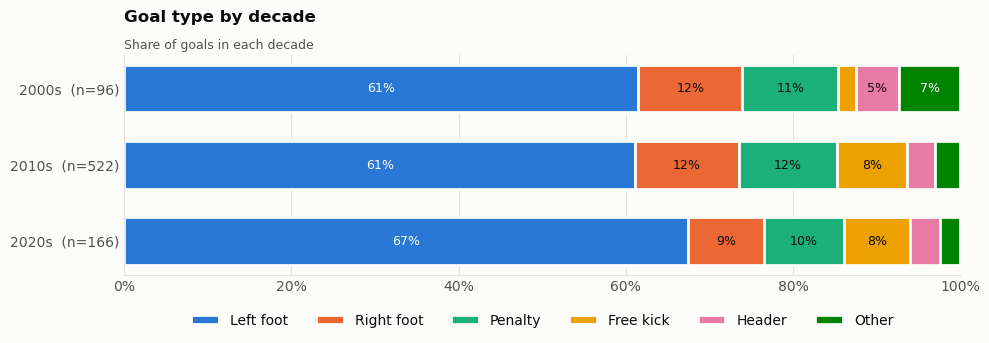

In [ ]:
# Fold the 3 "Unknown" goal types into "Other" so the chart has six groups.
goals["goal_type_chart"] = goals["goal_type"].replace({"Unknown": "Other"})
goal_type_order = ["Left foot", "Right foot", "Penalty", "Free kick", "Header", "Other"]
decade_order = ["2000s", "2010s", "2020s"]

type_counts = (
    pd.crosstab(goals["goal_decade"], goals["goal_type_chart"])
    .reindex(index=decade_order, columns=goal_type_order, fill_value=0)
)
type_shares = type_counts.div(type_counts.sum(axis=1), axis=0)

figure, axes = plt.subplots(figsize=(10, 3.6))
left_edges = np.zeros(len(type_shares))
y_positions = np.arange(len(type_shares))

for index, goal_type in enumerate(goal_type_order):
    shares = type_shares[goal_type].values
    axes.barh(
        y_positions, shares, left=left_edges, color=CATEGORICAL[index], height=0.62,
        edgecolor=SURFACE, linewidth=2, label=goal_type,
    )
    # Label segments wide enough to hold the text.
    for y_position, share, left_edge in zip(y_positions, shares, left_edges):
        if share >= 0.045:
            axes.text(
                left_edge + share / 2, y_position, f"{share:.0%}",
                ha="center", va="center", fontsize=9, color=LABEL_ON_FILL[index],
            )
    left_edges += shares

row_labels = [
    f"{decade}  (n={int(total)})" for decade, total in zip(type_counts.index, type_counts.sum(axis=1))
]
axes.set_yticks(y_positions)
axes.set_yticklabels(row_labels)
axes.invert_yaxis()
axes.set_xlim(0, 1)
axes.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
style_axes(axes, grid_axis="x")
axes.legend(frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.12))
add_title(axes, "Goal type by decade", "Share of goals in each decade")
save_figure(figure, "eda_goal_type_by_decade.png")

In [9]:
# Table view: counts behind the chart.
type_counts.assign(total=type_counts.sum(axis=1))

goal_type_chart,Left foot,Right foot,Penalty,Free kick,Header,Other,total
goal_decade,,,,,,,
2000s,59,12,11,2,5,7,96
2010s,319,65,61,44,17,16,522
2020s,112,15,16,13,6,4,166


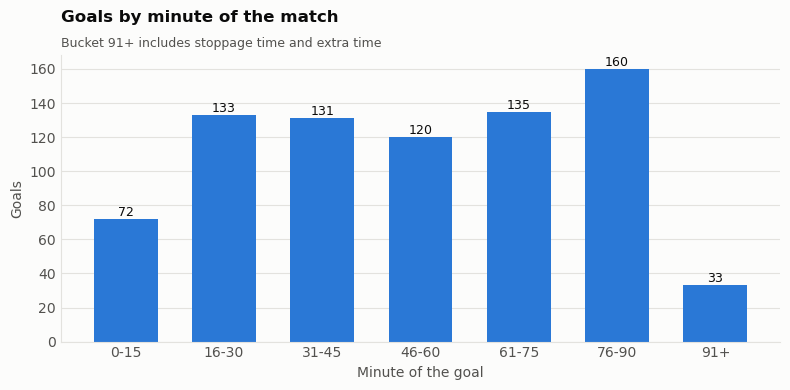

In [10]:
goals_by_bucket = goals["goal_minute_bucket"].value_counts().reindex(MINUTE_BUCKET_ORDER)

figure, axes = plt.subplots(figsize=(8, 4))
bars = axes.bar(goals_by_bucket.index.astype(str), goals_by_bucket.values, color=BLUE, width=0.65)
label_bars_vertical(axes, bars)
style_axes(axes)
axes.set_xlabel("Minute of the goal")
axes.set_ylabel("Goals")
add_title(axes, "Goals by minute of the match", "Bucket 91+ includes stoppage time and extra time")
save_figure(figure, "eda_goals_by_minute.png")

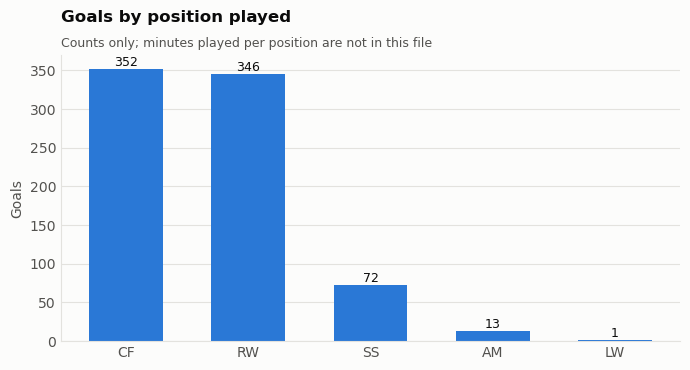

In [11]:
goals_by_position = goals["player_position"].value_counts()

figure, axes = plt.subplots(figsize=(7, 3.8))
bars = axes.bar(goals_by_position.index, goals_by_position.values, color=BLUE, width=0.6)
label_bars_vertical(axes, bars)
style_axes(axes)
axes.set_ylabel("Goals")
add_title(axes, "Goals by position played", "Counts only; minutes played per position are not in this file")
save_figure(figure, "eda_goals_by_position.png")

## 4. Match context

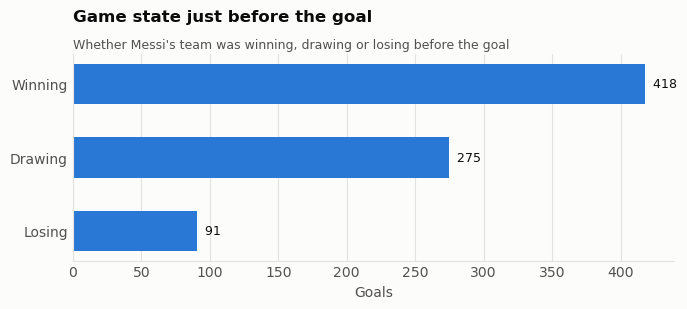

In [12]:
state_order = ["Winning", "Drawing", "Losing"]
goals_by_state = goals["game_state_before"].value_counts().reindex(state_order)

figure, axes = plt.subplots(figsize=(7, 3.2))
bars = axes.barh(goals_by_state.index, goals_by_state.values, color=BLUE, height=0.55)
label_bars_horizontal(axes, bars)
axes.invert_yaxis()
style_axes(axes, grid_axis="x")
axes.set_xlabel("Goals")
add_title(axes, "Game state just before the goal", "Whether Messi's team was winning, drawing or losing before the goal")
save_figure(figure, "eda_game_state.png")

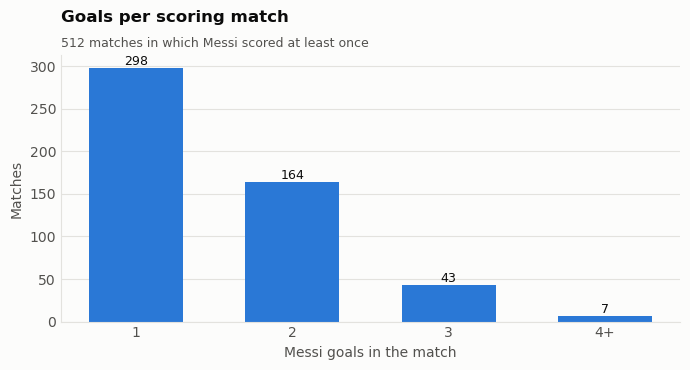

In [13]:
goals_in_match = goals.groupby("match_id").size()
capped = goals_in_match.clip(upper=4)
match_counts = capped.value_counts().sort_index()
match_labels = [str(value) if value < 4 else "4+" for value in match_counts.index]

figure, axes = plt.subplots(figsize=(7, 3.8))
bars = axes.bar(match_labels, match_counts.values, color=BLUE, width=0.6)
label_bars_vertical(axes, bars)
style_axes(axes)
axes.set_xlabel("Messi goals in the match")
axes.set_ylabel("Matches")
add_title(axes, "Goals per scoring match", f"{matches} matches in which Messi scored at least once")
save_figure(figure, "eda_goals_per_match.png")

In [14]:
home_away = pd.crosstab(goals["venue"], goals["match_result"]).reindex(columns=["W", "D", "L"], fill_value=0)
home_away["total"] = home_away.sum(axis=1)
print("Goals by venue and the final result of the match:")
home_away

Goals by venue and the final result of the match:


match_result,W,D,L,total
venue,,,,
Away,271,34,13,318
Home,424,29,13,466


## 5. Assists

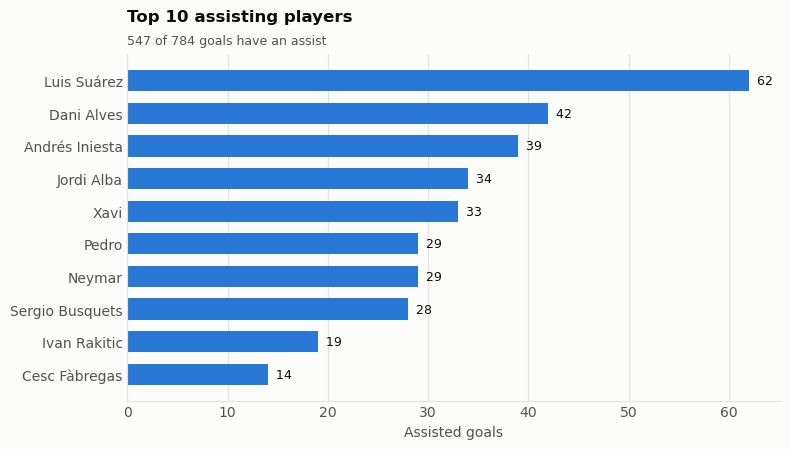

In [15]:
assisted = goals[goals["has_assist"]]
top_assisters = assisted["assist_player"].value_counts().head(10).sort_values()

figure, axes = plt.subplots(figsize=(8, 4.6))
bars = axes.barh(top_assisters.index, top_assisters.values, color=BLUE, height=0.65)
label_bars_horizontal(axes, bars)
style_axes(axes, grid_axis="x")
axes.set_xlabel("Assisted goals")
add_title(axes, "Top 10 assisting players", f"{len(assisted)} of {len(goals)} goals have an assist")
save_figure(figure, "eda_top_assisters.png")

In [16]:
# Share of goals with an assist, by decade and by goal type.
by_decade = goals.groupby("goal_decade")["has_assist"].mean().round(3).rename("share with assist")
by_type = goals.groupby("goal_type")["has_assist"].mean().round(3).rename("share with assist")
print(by_decade.to_string())
print()
print(by_type.sort_values().to_string())

goal_decade
2000s    0.740
2010s    0.690
2020s    0.699

goal_type
Free kick     0.000
Penalty       0.000
Other         0.375
Right foot    0.837
Left foot     0.884
Header        0.893
Unknown       1.000


## 6. Observations and candidate questions

### What the data shows (descriptive only)

1. **Volume.** 790 goals in 518 matches, or 1.53 goals per scoring match. 304 matches have one goal, 164 have two, 43 have three and 7 have four or more. LaLiga is 60% of all goals and the Champions League is 16%.
2. **Over time.** Goals per season rise from 7 in 2004-05 to a peak of 73 in 2011-12, stay between 38 and 60 for most Barcelona seasons, and drop to 27 in 2019-20. After the move to PSG the seasons show 11 and 21 goals, and Inter Miami shows 25, 25 and 30 (the last one is partial).
3. **Goal type.** Left-footed shots are 62% of all goals (61%, 61% and 67% in the three decades). Penalties are 11% (88 goals) and direct free kicks 7% (59 goals).
4. **Position.** Position is tied to the period. In the 2000s, 87 of 102 goals (85%) are from RW. In the 2010s CF (267) is ahead of RW (205), and SS appears for the first time (43). Position and decade therefore move together and cannot be separated by this file alone.
5. **Minute.** The 76-90 bucket has the most goals (161, 20%) and 0-15 has the fewest (74, 9%). Bucket 91+ has 33 goals.
6. **Game state.** 421 goals (53%) came while the team was already winning, 277 (35%) while drawing and 92 (12%) while losing.
7. **Assists.** 550 of 790 goals (70%) have an assist, from 86 different players. Penalties and direct free kicks never have one; among all other goals the share is about 86%. The most frequent assisters are Luis Suárez (62), Dani Alves (42) and Andrés Iniesta (39).
8. **Selection effect.** 88% of goals (697 of 790) came in matches that the team won. This is partly because only matches where Messi scored are in the file, so it must not be read as "the team wins when he scores" without a comparison group.

### Candidate questions for the next notebooks

| # | Question | Columns used | Enough data? | Caution |
|---|---|---|---|---|
| Q1 | How did scoring output change across seasons and clubs? | `season`, `club` | Yes | 2025-26 is partial; no minutes played, so output is not a rate |
| Q2 | How has the way he scores changed (goal types) over his career? | `goal_type`, `goal_decade`, `club` | Yes | The 2000s have only 102 goals; small groups are noisy |
| Q3 | How dependent are his goals on specific assisting partners, and does this change by era? | `assist_player`, `has_assist`, `season`, `club` | Yes | 86 assisters, so group the small ones |
| Q4 | When in the match do the goals come, and does it differ by competition or club? | `goal_minute_bucket`, `competition`, `club` | Yes | Bucket 91+ mixes stoppage time and extra time |
| Q5 | Do goals in knockout and final rounds look different from league goals? | `stage_name`, `competition` | Moderate | Finals have 33 goals; groups are small |
| Q6 | Does his position change over time, and how does it relate to goal type? | `player_position`, `season`, `goal_type` | Moderate | Counts of goals by position, not time spent there |

**Not answerable from this file:** shot efficiency or xG, goals per 90 minutes, goals per game, and anything about the national team. These need minutes played, shots or another data source.

Suggested next step as a team: choose four or five of Q1 to Q6, assign one notebook per question (`03_...`, `04_...`), and keep each notebook to one question.